# Pfeiffer Adapter
IndoBERT (`indobenchmark/indobert-base-p2`) | data sizes 5 / 10 / 50 / 100% | 5 seeds.

One bottleneck adapter per layer (after the feed-forward block), via the `adapters` library. `reduction_factor=12` gives a 64-dim bottleneck.

In [ ]:
!pip install -q datasets==5.0.1, accelerate==1.14.0, adapters==1.3.0
!pip install -q -U scikit-learn

import transformers, datasets, peft, accelerate, torch
print("transformers:", transformers.__version__, " (pinned)")
print("peft        :", peft.__version__, " (pinned)")
print("datasets    :", datasets.__version__, " (pinned)")
print("accelerate  :", accelerate.__version__, " (pinned)")
print("torch       :", torch.__version__, " (Colab-provided)")
print("CUDA avail  :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU         :", torch.cuda.get_device_name(0), " <- keep the same GPU type across methods")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 295.5/295.5 kB 7.3 MB/s eta 0:00:00
transformers: 4.57.6  (pinned)
peft        : 0.18.1  (pinned)
datasets    : 5.0.1  (pinned)
accelerate  : 1.14.0  (pinned)
torch       : 2.11.0+cu130  (Colab-provided)
CUDA avail  : True
GPU         : Tesla T4  <- keep the same GPU type across methods


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import sys
sys.path.append('/content/drive/MyDrive/thesis/code')   # folder containing utils.py
from utils import *

print("Data root    :", DATA_ROOT)
print("Results file :", RESULTS_PATH)
print("Seeds        :", SEEDS)
print("Data sizes   :", DATA_SIZES)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Data root    : /content/drive/MyDrive/thesis/data
Results file : /content/drive/MyDrive/thesis/results.csv
Seeds        : [42, 123, 456, 789, 2026]
Data sizes   : [100, 50, 10]


### Check data and progress

In [ ]:
validate_data_sizes() 
print()
print_status() 

 size_%                                folder  rows  actual_%_of_full  hoax_%
     10 /content/drive/MyDrive/thesis/data/10   848              10.0    50.0
     50 /content/drive/MyDrive/thesis/data/50  4244              50.0    50.0
    100    /content/drive/MyDrive/thesis/data  8486             100.0    50.0

val rows: 1212 | test rows: 2426 | full train rows: 8486
evaluation interval (steps per full-data epoch): 531
Data checks passed.

Completed seeds per (method, data size); target = 5; tag='main'
data_size  10   50   100
method                  
BitFit       5    5    5
FFT          5    5    5
Houlsby      5    5    5
IA3          5    5    5
LoRA         5    5    5
Total: 75 / 75 for methods present


### Model definition
`SeqBnConfig` = Pfeiffer-style.

In [7]:
import adapters
from adapters import SeqBnConfig

REDUCTION_FACTOR = 12   # 768 / 12 = 64-dim bottleneck
ADAPTER_NAME = "pfeiffer_adapter"

def build_pfeiffer_model():
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=2, id2label=ID2LABEL, label2id=LABEL2ID
    )
    adapters.init(model)
    model.add_adapter(ADAPTER_NAME, config=SeqBnConfig(reduction_factor=REDUCTION_FACTOR))
    model.set_active_adapters(ADAPTER_NAME)
    model.train_adapter(ADAPTER_NAME)   # prints the harmless warning described above

    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    print(f"trainable params: {trainable:,} || all params: {total:,} || trainable%: {100*trainable/total:.4f}")
    assert any(n.startswith("classifier") and p.requires_grad for n, p in model.named_parameters()), \
        "classifier head is frozen -- the model cannot learn the task"
    return model

### Run all data sizes and seeds
LR = 1e-4. Already-logged runs are skipped, so you can stop and re-run this cell after a disconnect. Set `RUN_SIZES = [100]` to do just the headline data size first.

In [ ]:
METHOD_NAME = "Pfeiffer"
LEARNING_RATE = 1e-4
TAG = "main"              
RUN_SIZES = DATA_SIZES    
RUN_SEEDS = SEEDS

In [9]:
for size in RUN_SIZES:
    for seed in RUN_SEEDS:
        run_experiment(
            method_name=METHOD_NAME,
            seed=seed,
            model_init_fn=build_pfeiffer_model,
            learning_rate=LEARNING_RATE,
            data_size=size,
            tag=TAG,
        )

print()
print_status(tag=TAG)


  Pfeiffer | data 100% | seed 42 | tag main | lr 0.0001


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

... (133 outputs left out)

trainable params: 1,191,170 || all params: 125,632,514 || trainable%: 0.9481
trainable parameters: 1,191,170 / 125,632,514 (0.9481%)


Step,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
531,0.235700,0.571758,0.863036,0.866630,0.863036,0.862700
1062,0.030800,0.826623,0.860561,0.869258,0.860561,0.859735
1593,0.014600,0.774017,0.869637,0.870040,0.869637,0.869601
2124,0.008400,0.890931,0.872112,0.872405,0.872112,0.872087
2655,0.005000,0.963551,0.872937,0.874410,0.872937,0.872812
3186,0.004100,0.990833,0.870462,0.871199,0.870462,0.870398
3717,0.007700,0.908395,0.875413,0.875438,0.875413,0.875410
4248,0.001200,1.006892,0.870462,0.870463,0.870462,0.870462
4779,0.001100,1.056035,0.872112,0.873995,0.872112,0.871951
5310,0.000000,1.088316,0.869637,0.869673,0.869637,0.869634


There were missing keys in the checkpoint model loaded: ['bert.prompt_tuning.base_model_embeddings.weight'].



TEST -- Acc 0.8784 | F1 0.8784 | val F1 0.8754 | VRAM 0.756 GB | 11.0 min | 5310 steps (10 evals, best @ step 3717)

Completed seeds per (method, data size); target = 5; tag='main'
data_size  10   50   100
method                  
BitFit       5    5    5
FFT          5    5    5
Houlsby      5    5    5
IA3          5    5    5
LoRA         5    5    5
Pfeiffer     5    5    5
Total: 90 / 90 for methods present


### Training curves
One seed per data size (the first in `RUN_SEEDS`). X-axis is the training step; the dashed line marks the checkpoint restored for test evaluation.

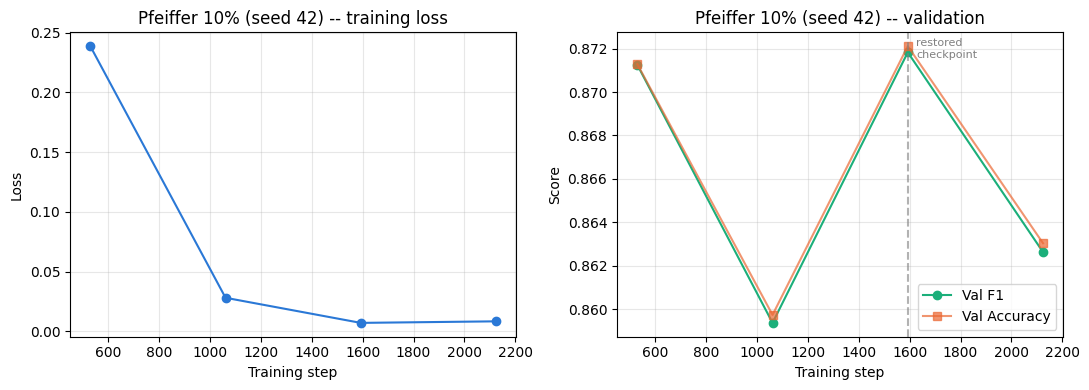

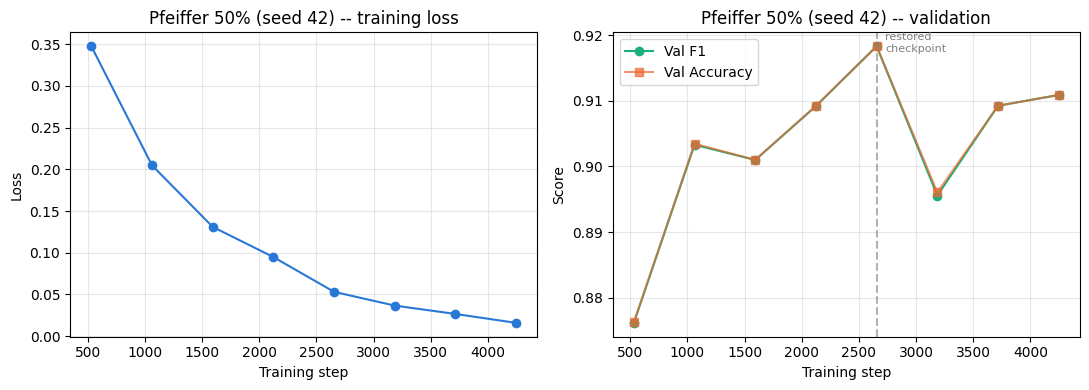

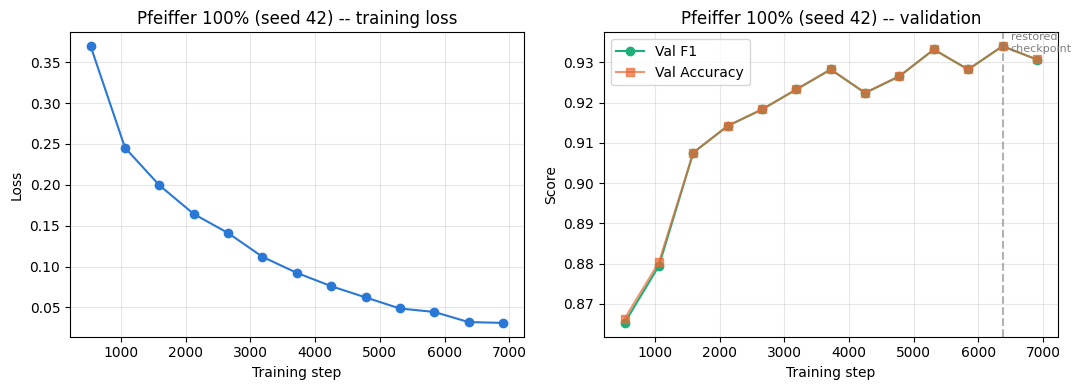

In [10]:
for size in sorted(RUN_SIZES):
    plot_training_curves(METHOD_NAME, RUN_SEEDS[0], size, TAG)

### Consistency across seeds
Validation F1 for all seeds overlaid, one chart per data size.

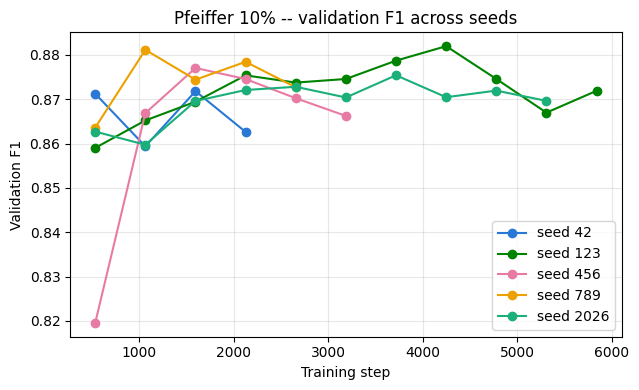

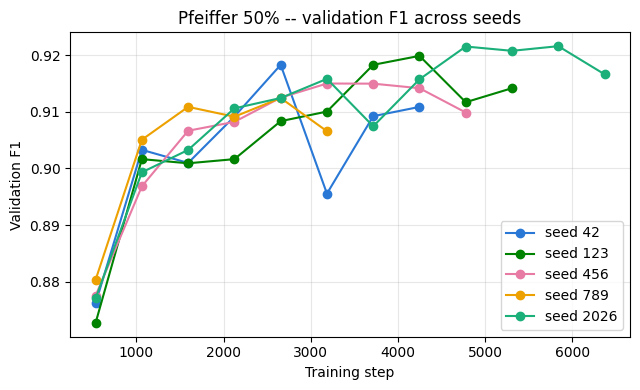

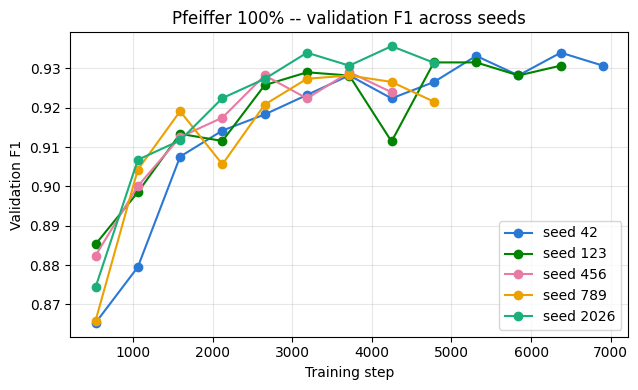

In [11]:
for size in sorted(RUN_SIZES):
    plot_seeds_overlay(METHOD_NAME, size, tag=TAG)

### Confusion matrices
Pooled over seeds, one per data size.

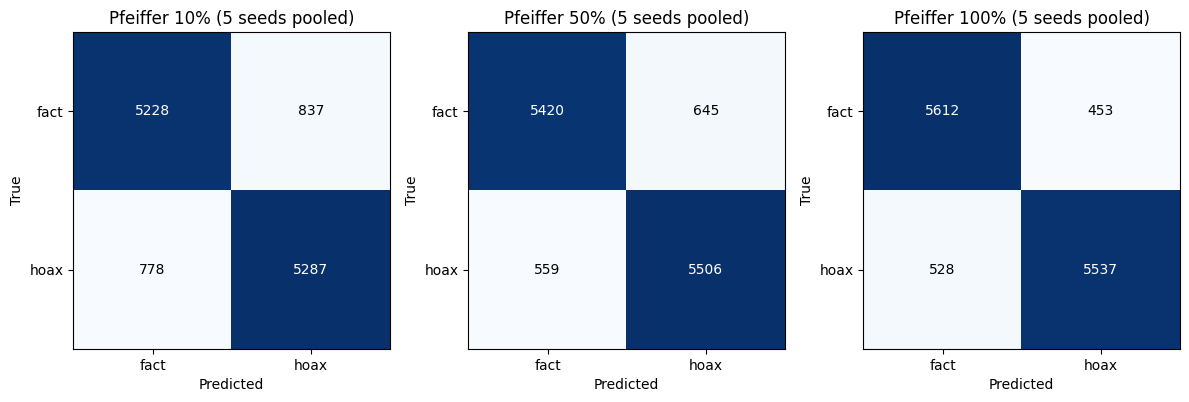

In [12]:
plot_confusion_matrices_by_size(METHOD_NAME, tag=TAG)

### Summary by data size
Mean +/- std over seeds: test vs. validation F1, generalization gap, training time.

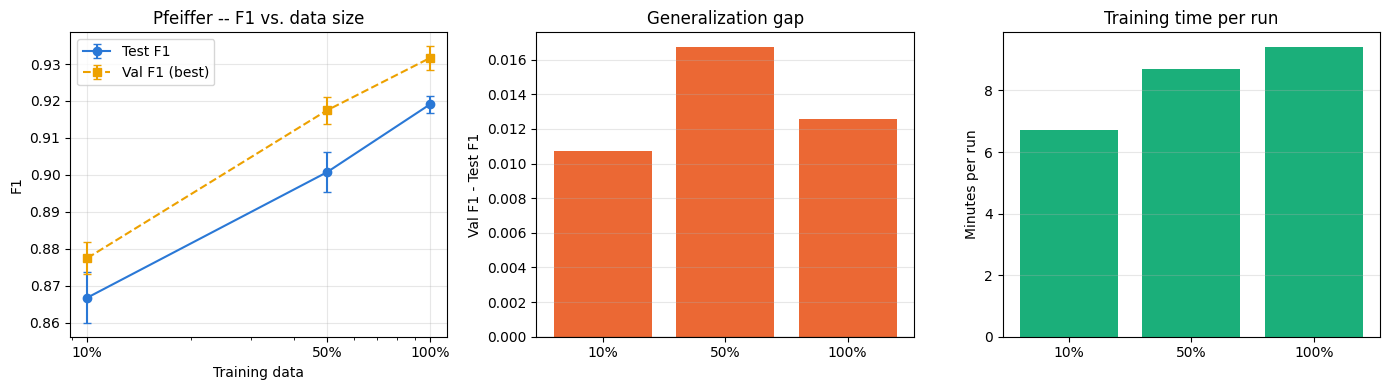

 data_size  seed  best_val_f1  accuracy       f1  trainable_pct  peak_vram_gb  total_time_s  epochs_run  steps_run
        10    42       0.8718  0.862325 0.862061         0.9481         0.756         234.3           4       2124
        10   123       0.8820  0.865622 0.865582         0.9481         0.756         565.7          11       5841
        10   456       0.8771  0.866447 0.866447         0.9481         0.756         311.3           6       3186
        10   789       0.8812  0.861500 0.861476         0.9481         0.756         244.5           5       2655
        10  2026       0.8754  0.878401 0.878372         0.9481         0.756         662.1          10       5310
        50    42       0.9183  0.901484 0.901482         0.9481         0.833         469.1           8       4248
        50   123       0.9199  0.908491 0.908452         0.9481         0.833         542.6          10       5310
        50   456       0.9150  0.900247 0.900247         0.9481         0.833   

In [13]:
plot_method_summary(METHOD_NAME, tag=TAG)